# Player Archetypes — training notebook

Trains K-Means **once, offline**, on a simulated player population whose per-game hours and
library sizes are calibrated on the public **Steam 200k** dataset. The frozen model is exported
later (Step 5) and served by the Python service, which assigns each real user to the nearest centre.

Every player — simulated here, real in the app — goes through the same
`archetype_features.compute_features`, so training and serving use identical features.

Runs locally (from `notebooks/`) or in Google Colab. Edit the paths in the first cell.

In [1]:
# --- Paths: edit these --------------------------------------------------------
REPO_URL  = "https://github.com/aljoharas/2026-GP1-Group8.git"
REPO_BRANCH = "feature/player-archetypes"
USE_DRIVE = False                                          # True: read the CSV from Google Drive
DRIVE_CSV = "/content/drive/MyDrive/loadout/steam-200k.csv"
SEED = 42

import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_DIR = Path("/content/2026-GP1-Group8")
    if not REPO_DIR.exists():
        !git clone -q -b {REPO_BRANCH} {REPO_URL} {REPO_DIR}
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# data/ is gitignored: in Colab without Drive, upload the CSV to this path
STEAM_CSV = Path(DRIVE_CSV) if USE_DRIVE else REPO_DIR / "data" / "steam-200k.csv"
DATA_DIR = REPO_DIR / "data"
FIGURES = REPO_DIR / "notebooks" / "figures"
DATA_DIR.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO_DIR / "backend" / "recommender"))
print("repo:", REPO_DIR, "| csv:", STEAM_CSV, "| exists:", STEAM_CSV.exists())

repo: /Users/aljoharaalsultan/Development/2026-GP1-Group8 | csv: /Users/aljoharaalsultan/Development/2026-GP1-Group8/data/steam-200k.csv | exists: True


In [2]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

import archetype_sim as sim
from archetype_features import FEATURE_NAMES, IMPUTED_FEATURES, MIN_GAMES, compute_features

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Chart style: one surface, recessive axes, a fixed categorical order
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MIXED = "#a3a29b"   # mixed players are not a persona, so they stay gray
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f09a99", "#c23a3a"])
PERSONA_COLORS = {**dict(zip(sim.PERSONA_NAMES, SERIES)), "mixed": MIXED}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 1. Steam 200k — calibration data

Keep only `play` rows with hours > 0, summed per (user, game). Per-game hours are capped at the
99th percentile of all plays (Steam counts idle time). The generator samples from users with
**≥ 5 played games**, the only players the model scores.

In [3]:
plays = sim.load_steam_plays(STEAM_CSV)
cal = sim.steam_calibration(plays)

library_all = plays.groupby("user_id").size()
hours_by_game = plays.groupby("game")["hours"].sum().sort_values(ascending=False)
players_by_game = plays["game"].value_counts()

facts = pd.Series({
    "(user, game) plays with hours > 0": len(plays),
    "users with any play": len(library_all),
    "median per-game hours (all plays)": plays["hours"].median(),
    "90th pct per-game hours (all plays)": plays["hours"].quantile(0.90),
    "99th pct = cap": cal["cap"],
    "median games played per user (all users)": library_all.median(),
    "users with >= 5 played games": len(cal["library_sizes"]),
    "median per-game hours (users >= 5, capped)": np.median(cal["hours"]),
    "90th pct per-game hours (users >= 5, capped)": np.quantile(cal["hours"], 0.90),
    "median library (users >= 5)": np.median(cal["library_sizes"]),
    "most-played game by hours": hours_by_game.index[0],
    "its share of all hours": hours_by_game.iloc[0] / hours_by_game.sum(),
    "most-played game by players": players_by_game.index[0],
}, dtype=object)
facts

(user, game) plays with hours > 0                  70477
users with any play                                11350
median per-game hours (all plays)                    4.5
90th pct per-game hours (all plays)                 76.0
99th pct = cap                                     908.0
median games played per user (all users)             1.0
users with >= 5 played games                        2436
median per-game hours (users >= 5, capped)           4.4
90th pct per-game hours (users >= 5, capped)        64.0
median library (users >= 5)                         12.0
most-played game by hours                         Dota 2
its share of all hours                          0.284929
most-played game by players                       Dota 2
dtype: object

**Known facts confirmed:** median per-game hours ≈ 4.5h and 90th percentile ≈ 76h over all plays;
the median user plays **1** game; about 2,400 users have ≥ 5 games; Dota 2 dominates by both hours
and player count (free-to-play / online skew, PC only).

In [4]:
# Save the empirical distributions the generator samples from
pd.Series(cal["hours"], name="hours").to_csv(DATA_DIR / "steam_game_hours.csv", index=False)
pd.Series(cal["library_sizes"], name="games_played").to_csv(DATA_DIR / "steam_library_sizes.csv", index=False)

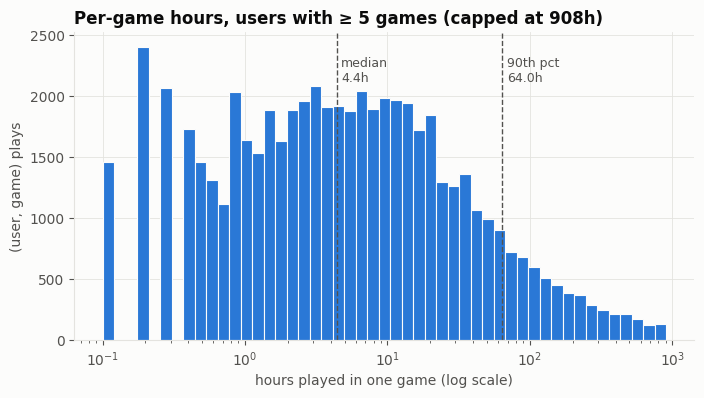

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(np.log10(cal["hours"].min()), np.log10(cal["cap"]), 50)
ax.hist(cal["hours"], bins=bins, color=SERIES[0], edgecolor=SURFACE, linewidth=0.8)
ax.set_xscale("log")
for q, label in [(0.5, "median"), (0.9, "90th pct")]:
    v = np.quantile(cal["hours"], q)
    ax.axvline(v, color=INK2, linewidth=1, linestyle="--")
    ax.text(v * 1.08, ax.get_ylim()[1] * 0.92, f"{label}\n{v:.1f}h", color=INK2, fontsize=9, va="top")
ax.set_title(f"Per-game hours, users with ≥ 5 games (capped at {cal['cap']:.0f}h)")
ax.set_xlabel("hours played in one game (log scale)")
ax.set_ylabel("(user, game) plays")
save(fig, "01_steam_game_hours")

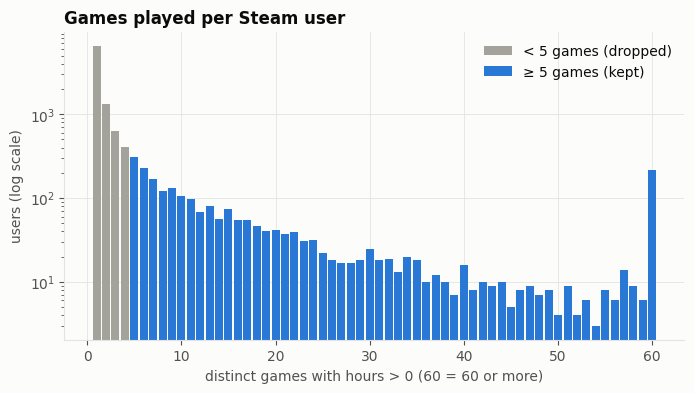

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sizes = library_all.clip(upper=60).value_counts().sort_index()
kept = sizes.index >= MIN_GAMES
ax.bar(sizes.index[~kept], sizes[~kept], width=0.85, color=MIXED, label="< 5 games (dropped)")
ax.bar(sizes.index[kept], sizes[kept], width=0.85, color=SERIES[0], label="≥ 5 games (kept)")
ax.set_yscale("log")
ax.set_title("Games played per Steam user")
ax.set_xlabel("distinct games with hours > 0 (60 = 60 or more)")
ax.set_ylabel("users (log scale)")
ax.legend(loc="upper right")
save(fig, "02_steam_library_sizes")

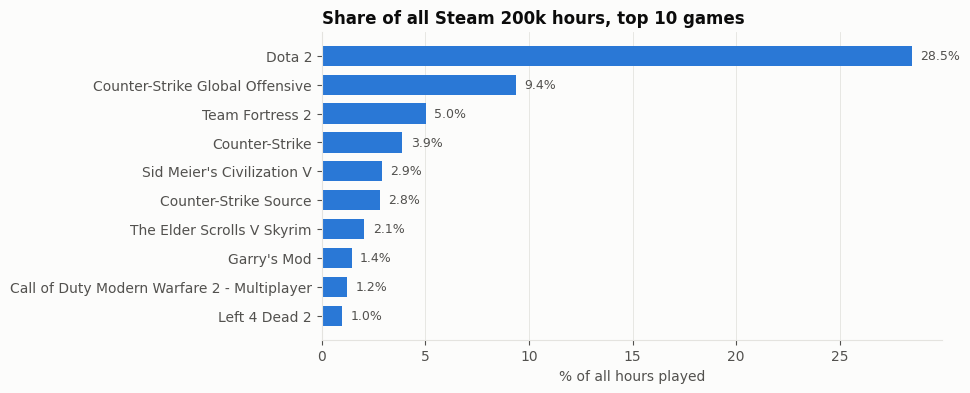

In [7]:
top = (hours_by_game.head(10) / hours_by_game.sum() * 100)[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top.index, top.values, color=SERIES[0], height=0.7)
for y, v in enumerate(top.values):
    ax.text(v + 0.4, y, f"{v:.1f}%", va="center", color=INK2, fontsize=9)
ax.set_title("Share of all Steam 200k hours, top 10 games")
ax.set_xlabel("% of all hours played")
ax.grid(axis="y", visible=False)
save(fig, "03_steam_top_games")

## 2. Simulated players → features → imputation → scaling

`generate_players` draws each player's **games** (hours, statuses, trophies, genres, online
flag, months); the features are then computed by the shared `compute_features`, never drawn directly.
All persona parameters are in `archetype_sim.PERSONAS`. 25% of the population are mixed
players (each game drawn from persona A with probability w ~ U(0.3, 0.7), else from B).

In [8]:
pd.DataFrame(sim.PERSONAS).T

,library_size,hours_quantiles,top_game_quantiles,completion_beta,trophy_beta,favourite_genres,favourite_share,online_beta,active_months
completionist,"(5, 15)","(0.25, 0.9)",None,"(8, 2)","(6, 4)","(3, 4)",0.7,"(2, 5)","(6, 12)"
explorer,"(10, 40)","(0.05, 0.6)",None,"(2.5, 4)","(2, 6)","(12, 12)",1.0,"(2, 5)","(6, 12)"
devotee,"(5, 10)","(0.05, 0.5)","(0.95, 0.995)","(3, 4)","(2, 6)","(1, 2)",0.85,"(2, 5)","(6, 12)"
competitor,"(5, 15)","(0.4, 0.95)",None,"(3, 4)","(2, 6)","(3, 4)",0.7,"(8, 2)","(6, 12)"
casual,"(5, 8)","(0.05, 0.5)",None,"(2, 4)","(2, 6)","(3, 4)",0.7,"(2, 5)","(2, 5)"


In [9]:
players = sim.generate_players(cal, n_per_persona=100, mix_share=0.25, seed=SEED)
persona = pd.Series([p["persona"] for p in players], name="persona")
group = persona.where(~persona.str.startswith("mixed:"), "mixed").rename("group")
is_pure = (group != "mixed").to_numpy()

raw = pd.DataFrame([compute_features(p["games"]) for p in players], columns=FEATURE_NAMES).astype(float)
print(len(players), "players:", group.value_counts().to_dict())
print("missing before imputation:", raw.isna().sum()[lambda s: s > 0].to_dict() or "none")

IMPUTE = raw[IMPUTED_FEATURES].mean()      # training means, exported with the model
X = raw.fillna(IMPUTE)
scaler = StandardScaler().fit(X)
Z = scaler.transform(X)
X.groupby(group).mean().round(2)

667 players: {'mixed': 167, 'completionist': 100, 'explorer': 100, 'devotee': 100, 'competitor': 100, 'casual': 100}
missing before imputation: none


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played
group,,,,,,,,
casual,0.32,0.26,0.81,0.87,0.31,1.51,0.33,1.97
competitor,0.46,0.28,0.86,2.67,0.30,3.34,0.78,2.45
completionist,0.80,0.67,0.83,2.18,0.34,2.78,0.27,2.34
devotee,0.42,0.29,0.30,1.50,0.96,3.65,0.31,2.06
explorer,0.41,0.28,0.95,1.08,0.19,1.65,0.28,2.71
mixed,0.48,0.36,0.69,1.70,0.57,3.03,0.40,2.35


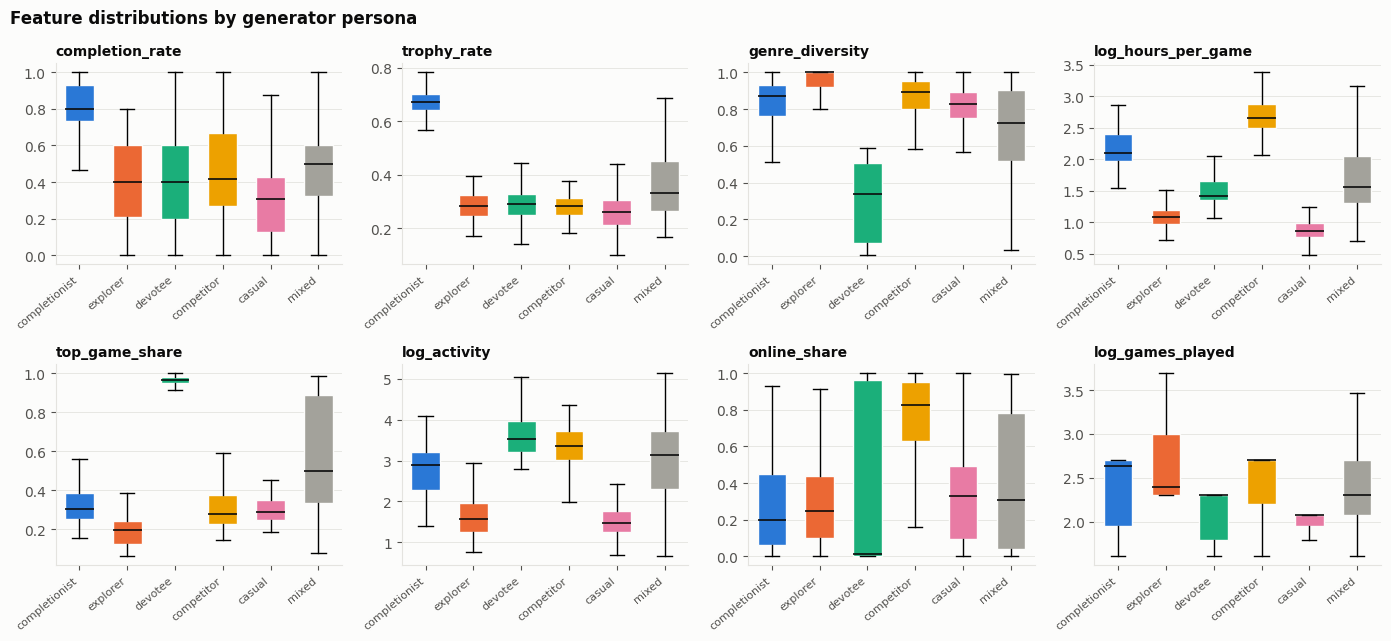

In [10]:
order = sim.PERSONA_NAMES + ["mixed"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, feature in zip(axes.flat, FEATURE_NAMES):
    data = [X.loc[group == g, feature] for g in order]
    box = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False,
                     medianprops={"color": INK, "linewidth": 1.2})
    for patch, g in zip(box["boxes"], order):
        patch.set(facecolor=PERSONA_COLORS[g], edgecolor=SURFACE, linewidth=1)
    ax.set_title(feature, fontsize=10)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=40, ha="right", fontsize=8)
    ax.grid(axis="x", visible=False)
fig.suptitle("Feature distributions by generator persona", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "04_features_by_persona")

## 3. Choosing k

Inertia (elbow) and mean silhouette for k = 2..8, each with `KMeans(n_init=20, random_state=42)`.

In [11]:
KS = list(range(2, 9))
inertia, silhouette = {}, {}
for k in KS:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    inertia[k], silhouette[k] = km.inertia_, silhouette_score(Z, km.labels_)
k_table = pd.DataFrame({"inertia": inertia, "silhouette": silhouette}).rename_axis("k")
best_k = int(k_table["silhouette"].idxmax())
k_table.round(3)

,inertia,silhouette
k,,
2,4002.834,0.278
3,2927.690,0.319
4,2350.452,0.347
5,2044.424,0.337
6,1783.151,0.348
7,1633.850,0.339
8,1522.819,0.300


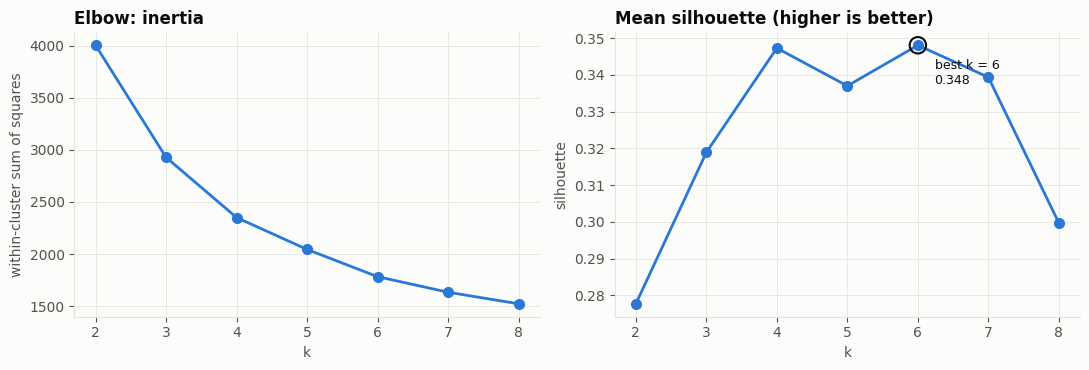

In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(KS, k_table["inertia"], color=SERIES[0], linewidth=2, marker="o", markersize=7)
a1.set_title("Elbow: inertia")
a1.set_xlabel("k"); a1.set_ylabel("within-cluster sum of squares")
a2.plot(KS, k_table["silhouette"], color=SERIES[0], linewidth=2, marker="o", markersize=7)
a2.scatter([best_k], [silhouette[best_k]], s=140, facecolor="none", edgecolor=INK, linewidth=1.5, zorder=3)
a2.annotate(f"best k = {best_k}\n{silhouette[best_k]:.3f}", (best_k, silhouette[best_k]),
            xytext=(12, -28), textcoords="offset points", color=INK, fontsize=9)
a2.set_title("Mean silhouette (higher is better)")
a2.set_xlabel("k"); a2.set_ylabel("silhouette")
for ax in (a1, a2):
    ax.set_xticks(KS)
fig.tight_layout()
save(fig, "05_choose_k")

**Does the choice depend on the generator seed?** Repeat the silhouette sweep on five other
simulated populations.

In [13]:
robust = {}
for s in range(5):
    p_s = sim.generate_players(cal, seed=s)
    raw_s = pd.DataFrame([compute_features(p["games"]) for p in p_s], columns=FEATURE_NAMES).astype(float)
    x_s = raw_s.fillna(raw_s[IMPUTED_FEATURES].mean())
    z_s = StandardScaler().fit_transform(x_s)
    robust[f"generator seed {s}"] = {
        k: silhouette_score(z_s, KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(z_s)) for k in KS
    }
robust = pd.DataFrame(robust).T
robust["best k"] = robust.idxmax(axis=1)
robust.round(3)

,2,3,4,5,6,7,8,best k
generator seed 0,0.264,0.303,0.335,0.349,0.355,0.334,0.324,6
generator seed 1,0.263,0.310,0.336,0.341,0.347,0.335,0.297,6
generator seed 2,0.267,0.311,0.341,0.330,0.333,0.320,0.316,4
generator seed 3,0.277,0.316,0.343,0.343,0.347,0.336,0.283,6
generator seed 4,0.273,0.311,0.342,0.343,0.344,0.329,0.320,6


### k justification (seed 42, starting persona parameters, 8 features)

- **There is no strong preference.** Silhouette is almost flat from k = 4 to k = 7
  (0.347 / 0.337 / 0.348 / 0.339). k = 6 is the highest, but only by 0.001 over k = 4, and the
  elbow has no sharp bend after 4. On the five other generator seeds k = 6 wins four times and
  k = 4 once, always by ≤ 0.01. Adding `log_games_played` lowered the best silhouette from 0.41
  (7 features, k = 5) to 0.35: the clusters overlap more.
- We take **k = 6** because it is the argmax and the most consistent winner across seeds, while
  stating that 4, 5 and 6 are close to equally supported.
- **Casual and explorer only partly separate.** With k = 6, 42 explorers form their own cluster
  (large libraries, near-maximal genre diversity) and 58 still sit with the casuals. About half
  of the simulated explorers have exactly 10 games (the Steam library sample clipped to 10–40
  piles up at 10, since the Steam median is 12), which makes them look like casuals with
  slightly more games. With k = 4 casual and explorer merge completely; with k = 5 the split is
  the same 42 / 58 but the devotees are one cluster.
- **Devotees still split by online share** (69 offline / 31 online), kept as two types.

In [14]:
K_OVERRIDE = None          # set an int here only after a reviewed decision
K = K_OVERRIDE or best_k
print("k =", K)

k = 6


## 4. Fit the model

In [15]:
model = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
labels = model.labels_
print("silhouette:", round(silhouette_score(Z, labels), 3))
print("cluster sizes:", pd.Series(labels).value_counts().sort_index().to_dict())

silhouette: 0.348
cluster sizes: {0: 114, 1: 186, 2: 127, 3: 124, 4: 56, 5: 60}


## 5. Stability

Refit with 10 other seeds. Adjusted Rand Index (ARI) compares two labelings regardless of cluster
numbering: 1 = identical, 0 = chance.

In [16]:
runs = [KMeans(n_clusters=K, n_init=20, random_state=s).fit_predict(Z) for s in range(1, 11)]
pairwise = [adjusted_rand_score(a, b) for a, b in itertools.combinations(runs, 2)]
vs_model = [adjusted_rand_score(labels, r) for r in runs]
print(f"mean pairwise ARI over 10 seeds (45 pairs): {np.mean(pairwise):.3f}  (min {np.min(pairwise):.3f})")
print(f"mean ARI vs the fitted model:              {np.mean(vs_model):.3f}  (min {np.min(vs_model):.3f})")

mean pairwise ARI over 10 seeds (45 pairs): 1.000  (min 1.000)
mean ARI vs the fitted model:              1.000  (min 1.000)


> **Stable is not the same as valid.** High stability on simulated data shows the *pipeline* is
> stable: the same population gives the same clusters whatever the seed. It does not show the
> archetypes are valid descriptions of real players. Validation comes later, from the real-player
> (survey) test of the frozen model.

## 6. Interpret the clusters

Centres in **original units** (`scaler.inverse_transform`), next to the persona averages.

In [17]:
centres = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_), columns=FEATURE_NAMES).rename_axis("cluster")
centres["players"] = pd.Series(labels).value_counts().sort_index()
centres.round(2)

,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played,players
cluster,,,,,,,,,
0,0.41,0.29,0.36,1.56,0.94,3.70,0.02,2.12,114
1,0.36,0.28,0.85,0.98,0.29,1.46,0.32,2.11,186
2,0.78,0.64,0.82,2.13,0.35,2.77,0.27,2.33,127
3,0.46,0.30,0.87,2.59,0.32,3.35,0.77,2.47,124
4,0.47,0.33,0.37,1.70,0.91,3.63,0.95,2.08,56
5,0.40,0.31,0.99,1.14,0.15,2.26,0.30,3.20,60


In [18]:
persona_means = X.groupby(group).mean().loc[order]
persona_means.round(2)

,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played
group,,,,,,,,
completionist,0.80,0.67,0.83,2.18,0.34,2.78,0.27,2.34
explorer,0.41,0.28,0.95,1.08,0.19,1.65,0.28,2.71
devotee,0.42,0.29,0.30,1.50,0.96,3.65,0.31,2.06
competitor,0.46,0.28,0.86,2.67,0.30,3.34,0.78,2.45
casual,0.32,0.26,0.81,0.87,0.31,1.51,0.33,1.97
mixed,0.48,0.36,0.69,1.70,0.57,3.03,0.40,2.35


In [19]:
composition = pd.crosstab(group, pd.Series(labels, name="cluster")).loc[order]
composition

cluster,0,1,2,3,4,5
group,,,,,,
completionist,1,0,99,0,0,0
explorer,0,58,0,0,0,42
devotee,69,0,0,0,31,0
competitor,0,1,1,97,1,0
casual,0,100,0,0,0,0
mixed,44,27,27,27,24,18


In [20]:
# Suggest a name per cluster: the pure persona whose average is nearest the centre (scaled space)
persona_z = pd.DataFrame(scaler.transform(persona_means.loc[sim.PERSONA_NAMES]), index=sim.PERSONA_NAMES)
dist = pd.DataFrame(
    [[np.linalg.norm(c - persona_z.loc[p]) for p in sim.PERSONA_NAMES] for c in model.cluster_centers_],
    columns=sim.PERSONA_NAMES,
).rename_axis("cluster")
suggested = dist.idxmin(axis=1).rename("nearest persona")
dupes = suggested[suggested.duplicated(keep=False)]
print("nearest persona per cluster:", suggested.to_dict())
if not dupes.empty:
    print("!! several clusters share a nearest persona:", dupes.to_dict())
dist.round(2)

nearest persona per cluster: {0: 'devotee', 1: 'casual', 2: 'completionist', 3: 'competitor', 4: 'devotee', 5: 'explorer'}
!! several clusters share a nearest persona: {0: 'devotee', 4: 'devotee'}


,completionist,explorer,devotee,competitor,casual
cluster,,,,,
0,4.20,4.23,0.87,4.01,3.73
1,3.76,1.44,3.81,3.46,0.42
2,0.21,3.49,4.11,3.15,3.81
3,3.19,3.20,3.79,0.18,3.58
4,4.29,4.56,1.90,3.27,4.03
5,3.82,1.28,4.75,3.37,2.99


### ⚠️ Cluster names — TO CONFIRM

Working names from the composition table and the nearest persona average ("The Main" and
"Devotee" are the team's working names for the online / offline devotee split). **These are not final.**

In [21]:
# >>> TO CONFIRM by the team before Step 5 (exported with the model) <<<
CLUSTER_NAMES = {
    0: "Devotee",         # one game is 94% of hours, offline (online share 0.02)
    1: "Casual",          # lowest hours per game and per month; all casuals + 58 explorers
    2: "Completionist",   # completion 0.78, trophies 0.64
    3: "Competitor",      # online share 0.77, longest sessions
    4: "The Main",        # one game is 91% of hours, and it is online (online share 0.95)
    5: "Explorer",        # most games (ln 3.2 ≈ 25), genre diversity 0.99, top game only 15%
}
assert sorted(CLUSTER_NAMES) == list(range(K)), "CLUSTER_NAMES must cover every cluster"

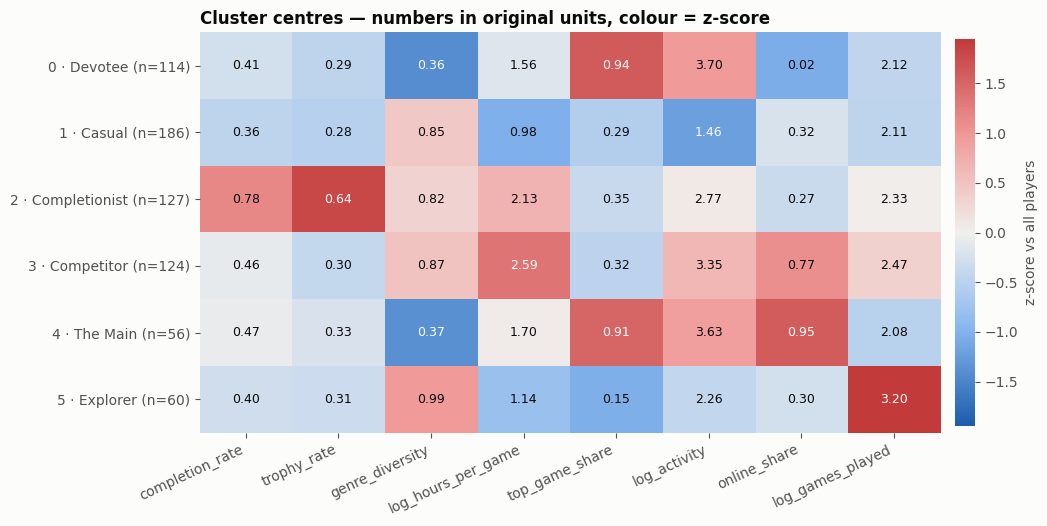

In [22]:
zc = pd.DataFrame(model.cluster_centers_, columns=FEATURE_NAMES)
fig, ax = plt.subplots(figsize=(10, 0.6 * K + 1.6))
lim = np.abs(zc.values).max()
im = ax.imshow(zc.values, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
for i in range(K):
    for j in range(len(FEATURE_NAMES)):
        z = zc.iloc[i, j]
        ax.text(j, i, f"{centres.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color=SURFACE if abs(z) > 0.6 * lim else INK)
ax.set_xticks(range(len(FEATURE_NAMES)), FEATURE_NAMES, rotation=25, ha="right")
ax.set_yticks(range(K), [f"{i} · {CLUSTER_NAMES[i]} (n={centres['players'][i]})" for i in range(K)])
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
cb.set_label("z-score vs all players", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Cluster centres — numbers in original units, colour = z-score")
save(fig, "06_cluster_centres")

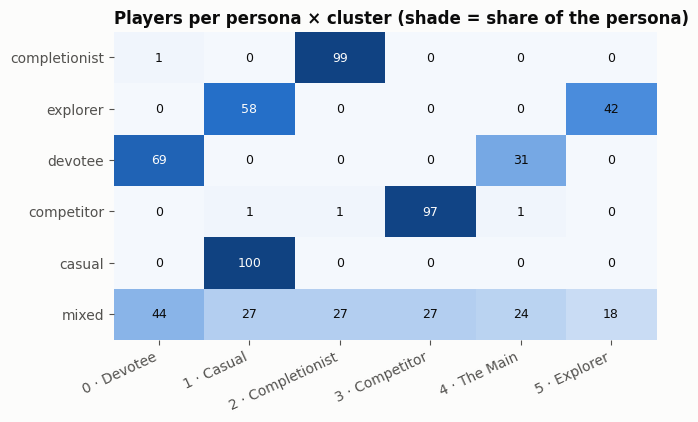

In [23]:
share = composition.div(composition.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(share.values, cmap=LinearSegmentedColormap.from_list("blue", ["#f4f8fd", "#2a78d6", "#104281"]),
          vmin=0, vmax=1, aspect="auto")
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, composition.iloc[i, j], ha="center", va="center", fontsize=9,
                color=SURFACE if share.iloc[i, j] > 0.55 else INK)
ax.set_xticks(range(K), [f"{i} · {CLUSTER_NAMES[i]}" for i in range(K)], rotation=25, ha="right")
ax.set_yticks(range(len(order)), order)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Players per persona × cluster (shade = share of the persona)")
save(fig, "07_persona_by_cluster")

## 7. Sanity check against the generator's labels

> **Sanity check only, not validation.** The personas were designed by us, so agreement only shows
> the pipeline recovers structure we put in; it says nothing about real players. Real validation
> comes later, from survey players scored by the frozen model.

In [24]:
ari_pure = adjusted_rand_score(group[is_pure], labels[is_pure])
print(f"ARI clusters vs persona labels (pure players only): {ari_pure:.3f}")

ARI clusters vs persona labels (pure players only): 0.725


## 8. 2D PCA view

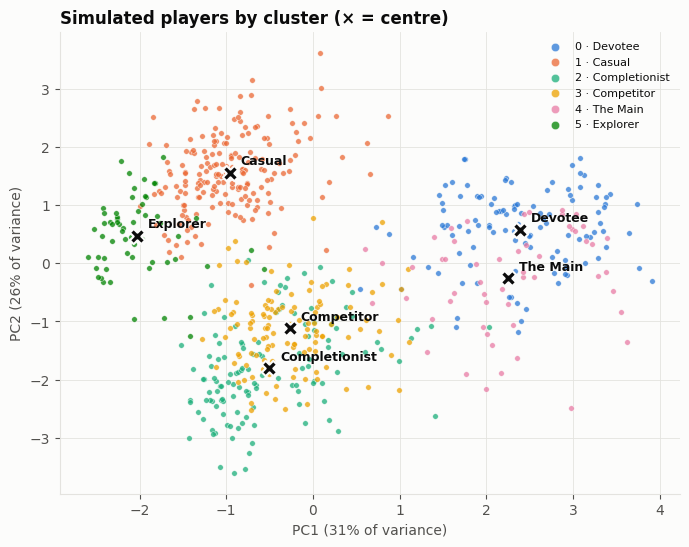

In [25]:
pca = PCA(n_components=2, random_state=SEED).fit(Z)
P2 = pca.transform(Z)
C2 = pca.transform(model.cluster_centers_)
ev = pca.explained_variance_ratio_

def pca_axes(ax, title):
    ax.set_title(title)
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")

fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    m = labels == c
    ax.scatter(P2[m, 0], P2[m, 1], s=16, color=SERIES[c], alpha=0.75, edgecolor=SURFACE, linewidth=0.4,
               label=f"{c} · {CLUSTER_NAMES[c]}")
ax.scatter(C2[:, 0], C2[:, 1], s=120, color=INK, marker="X", edgecolor=SURFACE, linewidth=1.5, zorder=3)
for c in range(K):
    ax.annotate(CLUSTER_NAMES[c], C2[c], xytext=(8, 6), textcoords="offset points", fontsize=9,
                fontweight="bold", color=INK)
ax.legend(loc="best", fontsize=8, markerscale=1.5)
pca_axes(ax, "Simulated players by cluster (× = centre)")
save(fig, "08_pca_clusters")

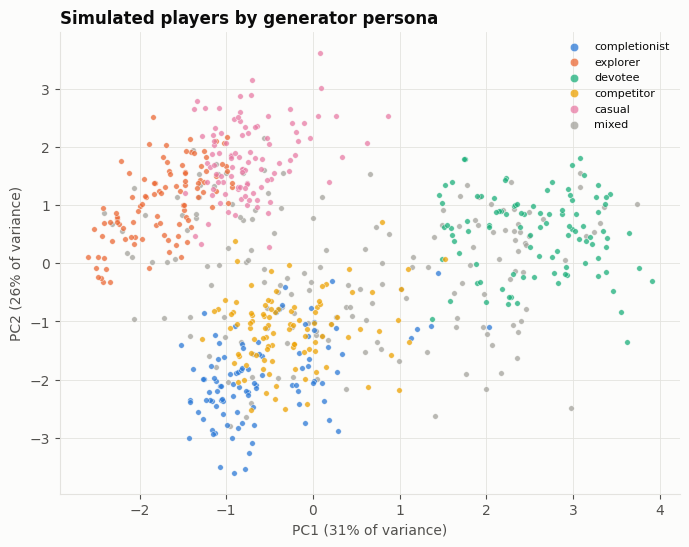

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))
for g in order:
    m = (group == g).to_numpy()
    ax.scatter(P2[m, 0], P2[m, 1], s=16, color=PERSONA_COLORS[g], alpha=0.75, edgecolor=SURFACE,
               linewidth=0.4, label=g, zorder=1 if g == "mixed" else 2)
ax.legend(loc="best", fontsize=8, markerscale=1.5)
pca_axes(ax, "Simulated players by generator persona")
save(fig, "09_pca_personas")

In [27]:
loadings = pd.DataFrame(pca.components_.T, index=FEATURE_NAMES, columns=["PC1", "PC2"])
loadings.round(2)

,PC1,PC2
completion_rate,-0.04,-0.47
trophy_rate,-0.09,-0.48
genre_diversity,-0.59,-0.09
log_hours_per_game,0.11,-0.56
top_game_share,0.61,0.06
log_activity,0.40,-0.38
online_share,-0.02,-0.20
log_games_played,-0.32,-0.17


## Summary for the checkpoint

In [28]:
print(f"k = {K} (silhouette {silhouette_score(Z, labels):.3f}); "
      f"stability mean pairwise ARI {np.mean(pairwise):.3f}; "
      f"sanity ARI vs personas {ari_pure:.3f}")
centres.round(2).assign(name=pd.Series(CLUSTER_NAMES))

k = 6 (silhouette 0.348); stability mean pairwise ARI 1.000; sanity ARI vs personas 0.725


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played,players,name
cluster,,,,,,,,,,
0,0.41,0.29,0.36,1.56,0.94,3.70,0.02,2.12,114,Devotee
1,0.36,0.28,0.85,0.98,0.29,1.46,0.32,2.11,186,Casual
2,0.78,0.64,0.82,2.13,0.35,2.77,0.27,2.33,127,Completionist
3,0.46,0.30,0.87,2.59,0.32,3.35,0.77,2.47,124,Competitor
4,0.47,0.33,0.37,1.70,0.91,3.63,0.95,2.08,56,The Main
5,0.40,0.31,0.99,1.14,0.15,2.26,0.30,3.20,60,Explorer
